In [7]:
import os, sys
import h5py
import numpy as np
import pandas as pd
import cv2
import torch
import time
from matplotlib import pyplot as plt

## Experiment Parameters

In [8]:
is_local = True # todo

if is_local:
    sys.path.append(r'C:/Users/w37262do/Documents/git/IR_preprocessing')
else:
    sys.path.append(r'/mnt/iusers01/eee01/w37262do/scratch/IR_preprocessing')
from src.preprocessing_tk import *

# Preprocessing protocol
protocol_name = sys.argv[-1] if not is_local else 'rubberband'

## Define Preprocessing Protocol

In [9]:
preprocessing_tk = get_processing_tk_from_name(protocol_name)

## Do Preprocessing & Saving Loop

In [10]:
save_base = r'G:\test_dir' if is_local else r'./'
raw_wavenumbers = np.load(r'D:/datasets/qcl2026_raw/wavenumbers.npy' if is_local else r'./wavenumbers.npy')
loop_start_time = time.time()

In [ ]:
print(f"Processing ...")
process_start_time = time.time()

# Import Data - AUS
h5_aus = h5py.File(
    r"F:/datasets/aus_qcl2026_raw/annotated_spectra_dataset.h5" if is_local else r'/mnt/eps01-rds/GardnerLab/aus_qcl2026_raw/annotated_spectra_dataset.h5'
)
spectra_aus = h5_aus['spectra'][:]
label_aus = h5_aus['tissue_class'][:]

# Import Data - NOCL
h5_nocl = h5py.File(
    r"D:/datasets/qcl2026_raw/annotated_spectra_dataset.h5" if is_local else r'/mnt/eps01-rds/GardnerLab/qcl2026_raw/annotated_spectra_dataset.h5'
)
spectra_nocl = h5_nocl['spectra'][:]
label_nocl = h5_nocl['tissue_class'][:]

# Process Data
processed_nocl, processed_wavenumbers = preprocessing_tk.spectral_transform(spectra_nocl,raw_wavenumbers)
processed_aus, processed_wavenumbers = preprocessing_tk.spectral_transform(spectra_aus,raw_wavenumbers)

# Re-save data
hf = h5py.File(fr"{save_base}/aus_qcl2026_processed/annotated_spectra_dataset.h5" , 'w')
hf.create_dataset('core_id', data=h5_aus['core_id'][:].astype(int), compression=None)
hf.create_dataset('patient_id', data=h5_aus['patient_id'][:].astype(int), compression=None)
hf.create_dataset('spectra', data=processed_aus.astype(np.float32), compression=None)
hf.create_dataset('tissue_class', data=h5_aus['tissue_class'][:].astype(int), compression=None)
hf.close()
hf = h5py.File(fr"{save_base}/qcl2026_processed/annotated_spectra_dataset.h5" , 'w')
hf.create_dataset('core_id', data=h5_nocl['core_id'][:].astype(int), compression=None)
hf.create_dataset('patient_id', data=h5_nocl['patient_id'][:].astype(int), compression=None)
hf.create_dataset('spectra', data=processed_nocl.astype(np.float32), compression=None)
hf.create_dataset('tissue_class', data=h5_nocl['tissue_class'][:].astype(int), compression=None)
hf.close()

np.save(fr"{save_base}/qcl2026_processed/wavenumbers.npy" ,processed_wavenumbers)
np.save(fr"{save_base}/aus_qcl2026_processed/wavenumbers.npy" ,processed_wavenumbers)

# Finish
h5_aus.close()
h5_nocl.close()
process_time = time.time() - process_start_time
if not is_local: np.save(r'./wavenumbers.npy',processed_wavenumbers)
print(f"Finished processing all spectra!")
print(f"Processing completed in {process_time:.3F} seconds")

Processing ...


## Plot Figures

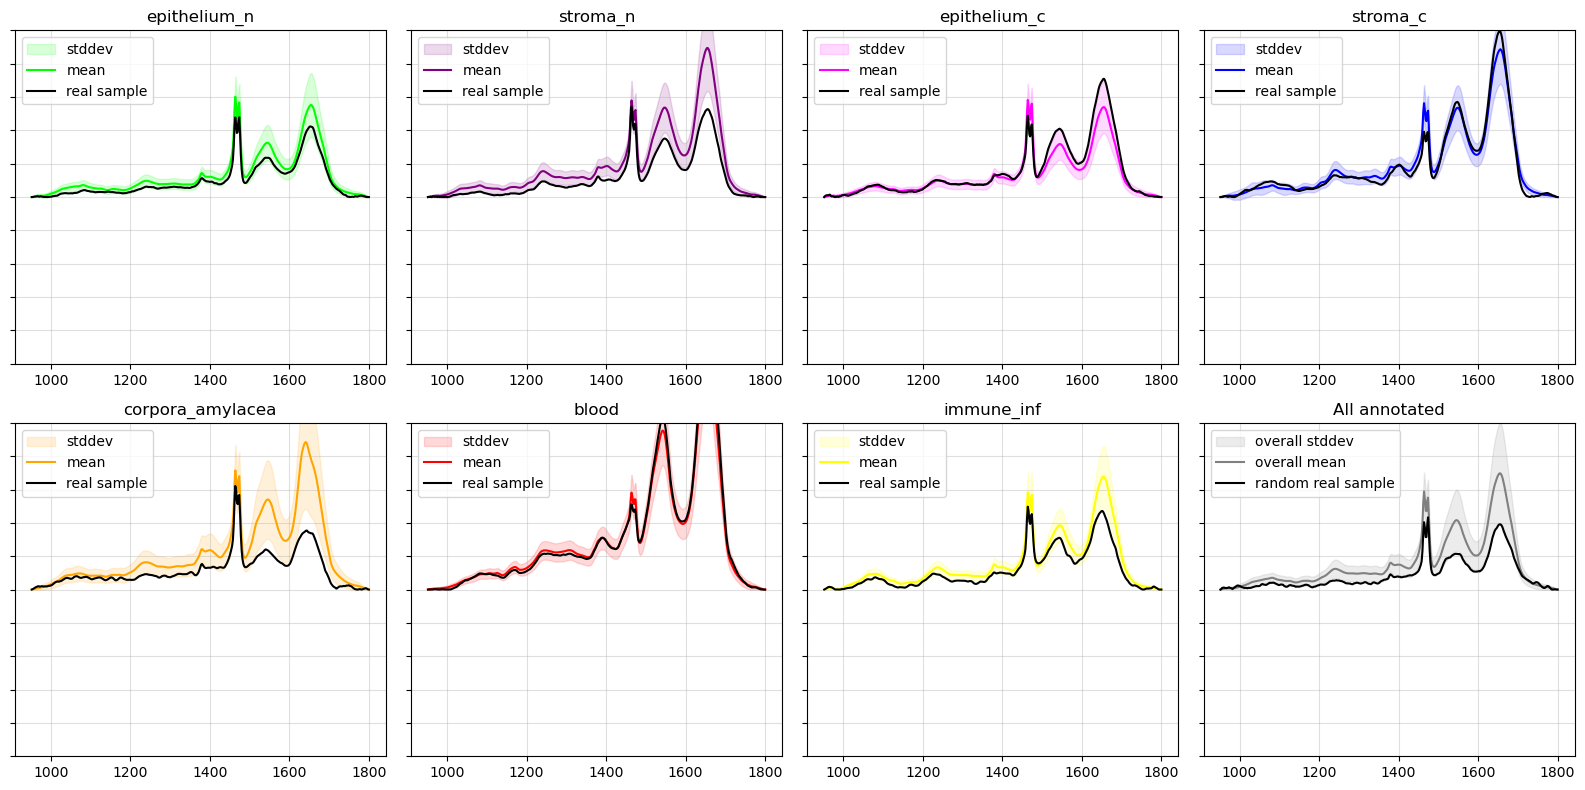

In [6]:
annotation_class_colors = np.array([[0,255,0],[128,0,128],[255,0,255],[0,0,255],[255,165,0],[255,0,0], [255,255,0]]) / 255.0
annotation_class_names = np.array(['epithelium_n','stroma_n','epithelium_c','stroma_c','corpora_amylacea','blood','immune_inf'])

fig,ax = plt.subplots(2,4,figsize=(16,8)); ax = ax.flatten()

spec_mean,spec_std = np.mean(processed_nocl,0),np.std(processed_nocl,0)
vmax = spec_mean.max() + spec_std[spec_mean.argmax()]; vmin = -vmax
ax[7].fill_between(processed_wavenumbers,spec_mean-spec_std,spec_mean+spec_std,color='gray',alpha=0.15,label=f'overall stddev')
ax[7].plot(processed_wavenumbers,spec_mean,color='gray',label=f'overall mean')
ax[7].plot(processed_wavenumbers,processed_nocl[len(processed_nocl)//2],color='k',label=f'random real sample')
ax[7].grid(alpha=0.4); ax[7].legend(); ax[7].set_title(f'All annotated')
ax[7].set_ylim(ymin=vmin,ymax=vmax)
ax[7].set_yticks(np.linspace(vmin,vmax,11),labels=[])

for cls in range(len(annotation_class_names)):
    class_spec = processed_nocl[np.where(label_nocl==cls)]
    class_mean,class_std = np.mean(class_spec,0),np.std(class_spec,0)
    ax[cls].fill_between(processed_wavenumbers,class_mean-class_std,class_mean+class_std,color=annotation_class_colors[cls],alpha=0.15,label=f'stddev')
    ax[cls].plot(processed_wavenumbers,class_mean,color=annotation_class_colors[cls],label=f'mean')
    ax[cls].plot(processed_wavenumbers,class_spec[len(class_spec)//2],color='k',label=f'real sample')
    ax[cls].grid(alpha=0.4); ax[cls].legend(); ax[cls].set_title(f'{annotation_class_names[cls]}')
    ax[cls].set_ylim(ymin=vmin,ymax=vmax)
    ax[cls].set_yticks(np.linspace(vmin,vmax,11),labels=[])

fig.tight_layout()

## Save Processing Results

In [ ]:
if not is_local:
    if os.path.isfile(f'results_processing.txt'):
        f = open(f'results_processing.txt', 'r')
        lines = f.readlines()
        f.close()
    else:
        lines = [x + ', \n' for x in ['protocol_name','spectra_processed','total_time']]

    # Process files
    lines[0] = lines[0].replace(f'\n', f'{protocol_name}, \n')
    lines[1] = lines[1].replace(f'\n', f'{len(processed_nocl)+len(processed_aus)}, \n')
    lines[2] = lines[2].replace(f'\n', f'{process_time}, \n')

    f = open(f'results_processing.txt', 'w')
    f.write(''.join(lines))
    f.close()